# 02 · Results — test set

Run after training:

```bash
python -m src.evaluate          # test set, once
python -m src.report
python -m src.export --benchmark
```
This notebook reads those outputs and adds a patient-level view.

In [1]:
import os, sys, json
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, '.')
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
SPLIT = 'test'
OUT = f'reports/eval/{SPLIT}'
df = pd.read_csv(f'{OUT}/per_patient.csv')
display(Markdown(open(f'{OUT}/results.md').read()))

# Results — test set (56 patients)

Best model by validation Dice: **ResNet34 U-Net** (val mean Dice 0.825). Values are mean (median) over patients.

## Model comparison (no TTA)

| model | Dice WT | Dice TC | Dice ET | HD95 WT (mm) | HD95 TC (mm) | HD95 ET (mm) | \|vol err\| WT (mL) | \|vol err\| TC (mL) | \|vol err\| ET (mL) |
|---|---|---|---|---|---|---|---|---|---|
| Attention U-Net | 0.906 (0.933) | 0.829 (0.901) | 0.783 (0.861) | 7.7 (3.2) | 8.2 (5.4) | 27.3 (2.1) | 7.6 (4.8) | 6.2 (2.0) | 2.4 (1.6) |
| ResNet34 U-Net | 0.900 (0.920) | 0.834 (0.906) | 0.787 (0.864) | 19.6 (6.0) | 8.1 (3.3) | 24.6 (2.0) | 7.6 (4.4) | 6.0 (1.8) | 2.5 (1.4) |
| ResNet34 U-Net (no modality dropout) | 0.903 (0.930) | 0.835 (0.903) | 0.760 (0.860) | 12.8 (4.0) | 8.8 (5.2) | 32.0 (2.1) | 6.3 (2.9) | 5.7 (2.2) | 2.6 (1.5) |
| U-Net | 0.902 (0.924) | 0.826 (0.880) | 0.793 (0.868) | 8.7 (3.7) | 9.2 (6.4) | 27.2 (2.2) | 7.7 (5.9) | 5.7 (2.1) | 2.3 (1.2) |

## Test-time augmentation

| model | Dice WT: plain → TTA | Dice TC: plain → TTA | Dice ET: plain → TTA | seconds/patient: plain → TTA |
|---|---|---|---|---|
| Attention U-Net | 0.906 → 0.909 (+0.002) | 0.829 → 0.835 (+0.006) | 0.783 → 0.791 (+0.007) | 2.4 → 3.7 |
| ResNet34 U-Net | 0.900 → 0.903 (+0.004) | 0.834 → 0.839 (+0.005) | 0.787 → 0.791 (+0.004) | 2.2 → 3.2 |
| ResNet34 U-Net (no modality dropout) | 0.903 → 0.905 (+0.002) | 0.835 → 0.843 (+0.007) | 0.760 → 0.783 (+0.023) | 2.2 → 3.2 |
| U-Net | 0.902 → 0.903 (+0.001) | 0.826 → 0.832 (+0.006) | 0.793 → 0.796 (+0.003) | 2.3 → 3.4 |

## Missing-sequence test (mean Dice WT / TC / ET)

| removed sequence | ResNet34 U-Net: WT / TC / ET | ResNet34 U-Net (no modality dropout): WT / TC / ET |
|---|---|---|
| — (all 4) | 0.900 / 0.834 / 0.787 | 0.903 / 0.835 / 0.760 |
| FLAIR | 0.834 / 0.800 / 0.765 | 0.583 / 0.746 / 0.717 |
| T1 | 0.893 / 0.801 / 0.772 | 0.885 / 0.789 / 0.743 |
| T1CE | 0.895 / 0.658 / 0.342 | 0.887 / 0.412 / 0.049 |
| T2 | 0.889 / 0.822 / 0.783 | 0.875 / 0.784 / 0.771 |

## Does uncertainty point at errors? (WT)

| model | TTA | AUROC (uncertainty → error) | error rate, 1% most uncertain voxels | error rate, other voxels |
|---|---|---|---|---|
| Attention U-Net | no | 0.975 | 28.2% | 0.73% |
| Attention U-Net | yes | 0.975 | 27.1% | 0.71% |
| ResNet34 U-Net | no | 0.972 | 30.0% | 0.79% |
| ResNet34 U-Net | yes | 0.974 | 29.1% | 0.76% |
| ResNet34 U-Net (no modality dropout) | no | 0.973 | 28.6% | 0.72% |
| ResNet34 U-Net (no modality dropout) | yes | 0.975 | 27.8% | 0.70% |
| U-Net | no | 0.973 | 29.5% | 0.77% |
| U-Net | yes | 0.974 | 28.9% | 0.77% |

## Why the worst patients fail

- **BraTS20_Training_266** (Dice 0.94 / 0.40 / 0.00): low-grade glioma (under-represented: ~20% of training data); no ET in the expert label but 0.2 mL predicted (Dice 0 by definition); WT HD95 74 mm: false-positive region far from the tumor
- **BraTS20_Training_335** (Dice 0.91 / 0.58 / 0.00): low-grade glioma (under-represented: ~20% of training data); no ET in the expert label but 0.6 mL predicted (Dice 0 by definition)
- **BraTS20_Training_280** (Dice 0.83 / 0.15 / 0.59): low-grade glioma (under-represented: ~20% of training data); tiny true TC (0.83 mL): a few voxels decide Dice; WT HD95 88 mm: false-positive region far from the tumor


## Per-patient Dice by model

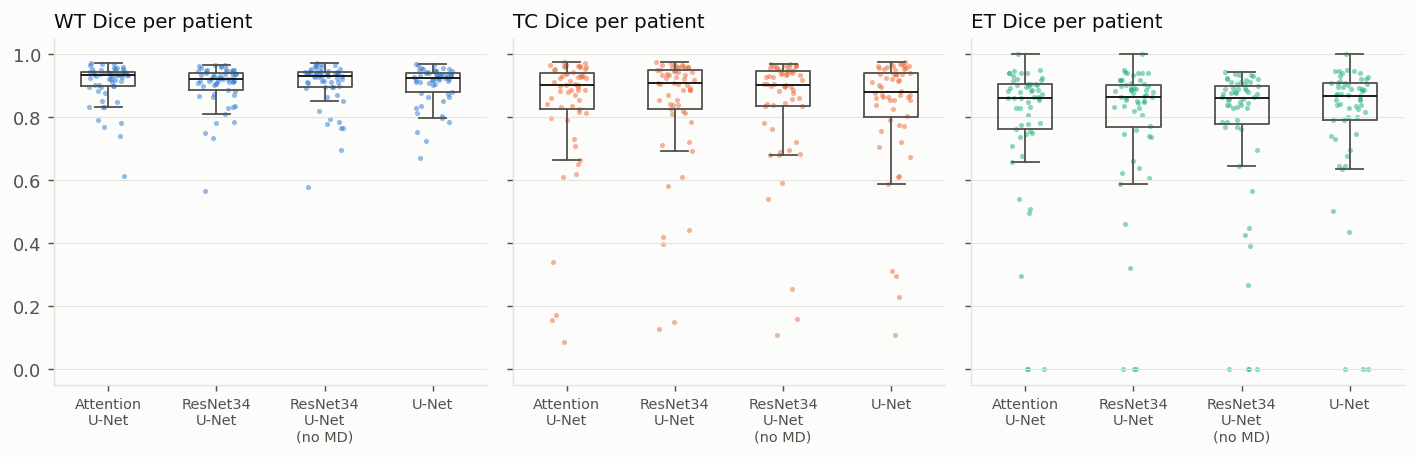

In [2]:
Image(f'{OUT}/model_comparison.png')

## Missing-sequence test
Each sequence removed in turn, for the ResNet34 U-Net trained with and without modality dropout.

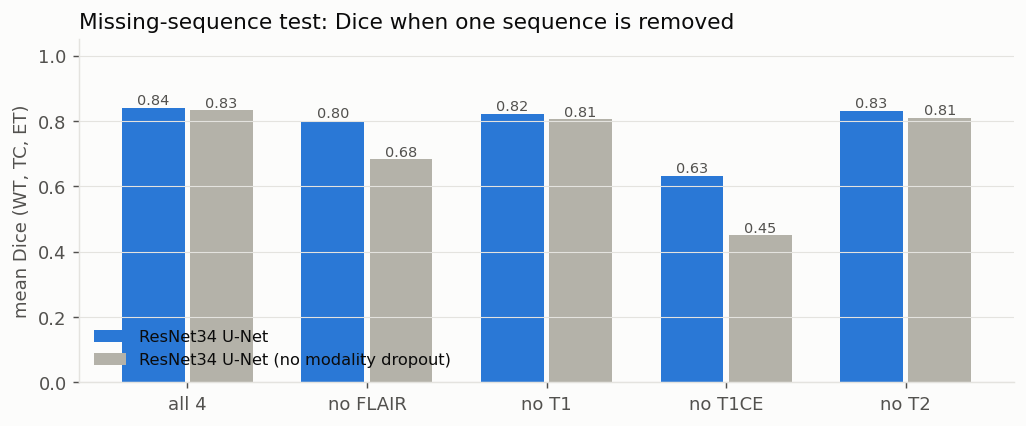

In [3]:
Image(f'{OUT}/missing_sequences.png')

## Best and worst patients
The reasons listed in the results above are derived from each patient's metrics (tumor size, grade, distance errors, volume ratio).

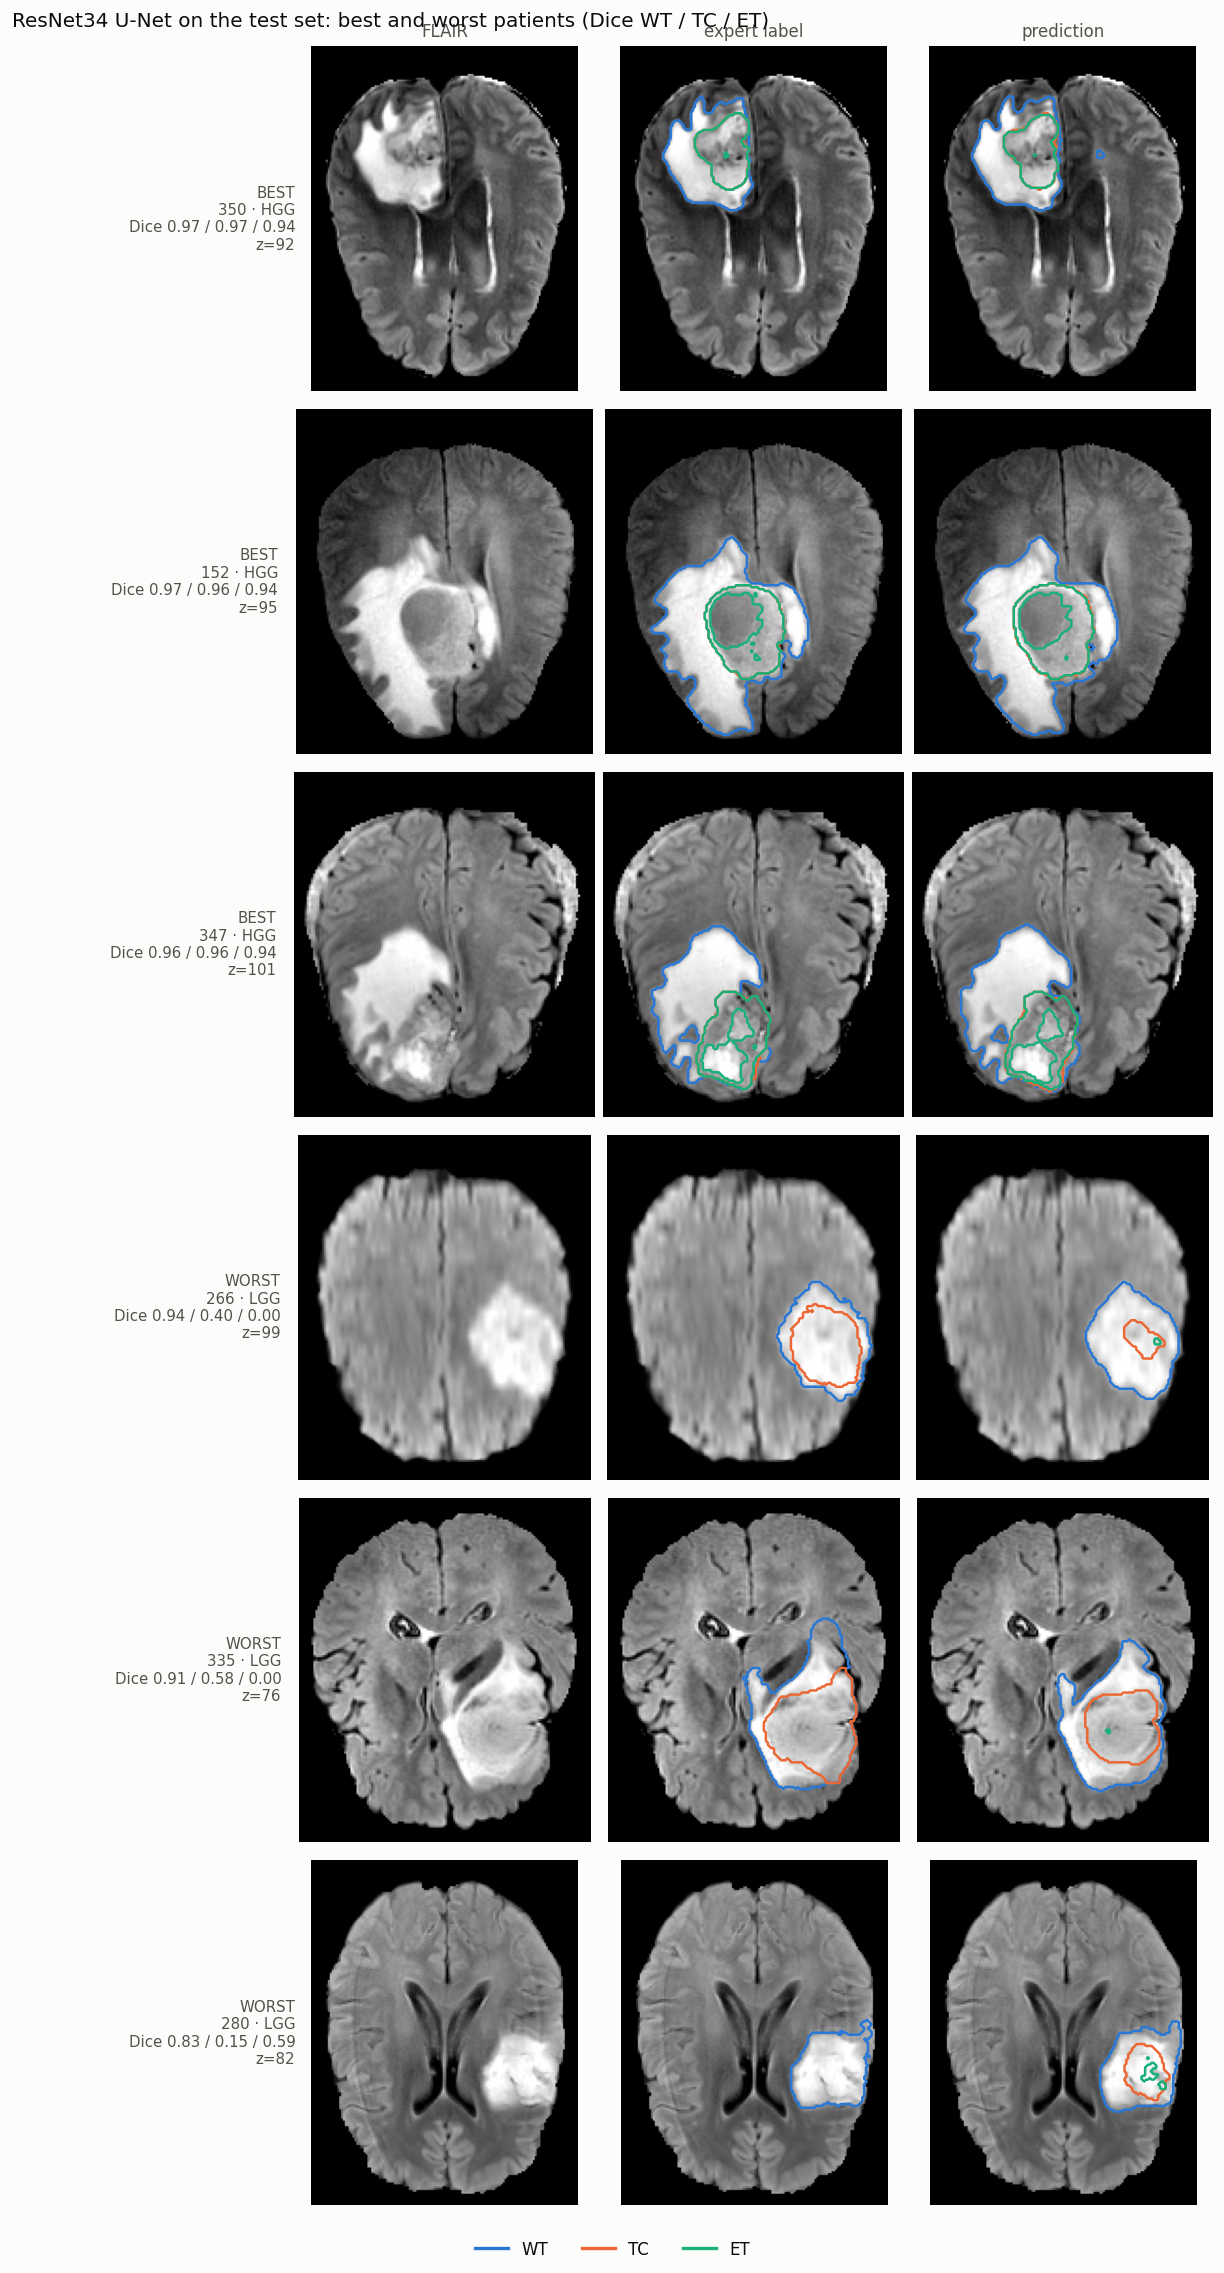

In [4]:
Image(f'{OUT}/gallery.png')

## Does the uncertainty map point at the errors?
AUROC = how well per-voxel uncertainty separates wrong from right voxels inside the brain (0.5 = no better than chance).

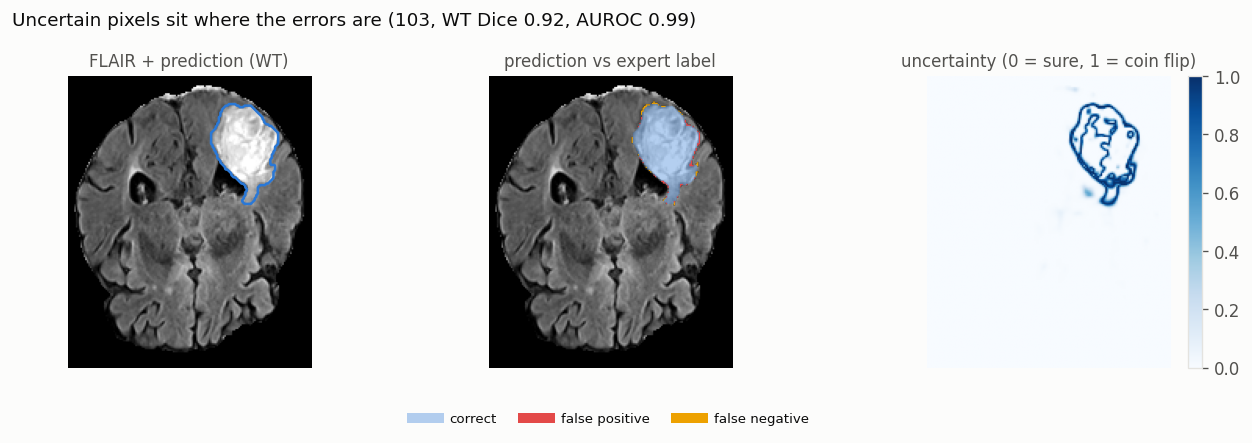

unc_auroc_WT  err_top1pct_WT  err_rest_WT
model          tta                                             
attunet        False         0.975           0.282        0.007
               True          0.975           0.271        0.007
resunet34      False         0.972           0.300        0.008
               True          0.974           0.291        0.008
resunet34_nomd False         0.973           0.286        0.007
               True          0.975           0.278        0.007
unet           False         0.973           0.295        0.008
               True          0.974           0.289        0.008

In [5]:
display(Image(f'{OUT}/uncertainty.png'))
df[df['drop'].isna()].groupby(['model', 'tta'])[['unc_auroc_WT', 'err_top1pct_WT', 'err_rest_WT']].mean().round(3)

## Volume agreement (mL)
Voxels are 1 mm³, so predicted volumes can be compared directly with the expert's.

In [6]:
best = json.load(open(f'{OUT}/best_model.json'))['best']
d = df[(df.model == best) & ~df.tta.astype(bool) & df['drop'].isna()]
d[[f'vol_err_{r}' for r in ['WT', 'TC', 'ET']]].describe().round(1)

,vol_err_WT,vol_err_TC,vol_err_ET
count,56.0,56.0,56.0
mean,1.4,-3.7,-0.1
std,10.8,12.5,4.3
min,-37.1,-70.5,-22.9
25%,-1.5,-3.3,-1.2
50%,2.7,-0.2,-0.1
75%,5.1,1.1,1.5
max,30.8,12.9,8.6


## Patient-level view
Tumor area per slice and a 3D view for one test patient (the same views as the app).

In [7]:
from src.brats_io import BraTSSource, check_and_load
from src.inference import TorchPredictor, load_model, predict_volume, to_regions
from src.utils import load_config, get_device
from src import viz
cfg = load_config(); dev = get_device()
pred = TorchPredictor(load_model(f'models/{best}.pt', dev)[0], dev)
pid = d.sort_values('dice_WT').iloc[len(d) // 2].pid      # a typical patient
vol, seg, _ = check_and_load(BraTSSource(cfg['raw_path']), pid)
res = predict_volume(pred, vol, cfg)
reg = to_regions(res['probs'].astype(np.float32))
print(pid, {r: f'{reg[i].sum() / 1000:.1f} mL' for i, r in enumerate(['WT', 'TC', 'ET'])})
viz.area_chart(reg).show()
viz.view_3d(reg, res['brain']).show()

/home/user/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BraTS20_Training_055 {'WT': '130.0 mL', 'TC': '18.0 mL', 'ET': '11.0 mL'}


## Speed (ONNX export)

In [8]:
# written by `python -m src.export --benchmark` on the machine you want to time
p = 'reports/benchmark.json'
json.load(open(p)) if os.path.exists(p) else print('no benchmark yet: run python -m src.export --benchmark')

no benchmark yet: run python -m src.export --benchmark
